In [151]:
# ──  Dependencies ──────────────────────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
for pkg in ['rdkit','xgboost','imbalanced-learn','scikit-learn',
            'matplotlib','seaborn','openpyxl','torch','torch-geometric']:
    try: __import__(pkg.replace('-','_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')

Dependencies OK.


In [152]:
# ── Imports ────────────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


---
## Step 1 — Data Loading, Curation & Label Assignment

**Primary dataset**: DILIrank Gold Standard (1,111 compounds) — curated clinical in vivo DILI labels.  
**Supplementary**: LTKB-BD (FDA, AID 625276/277/278) — merged and deduplicated.

| Label | Meaning |
|---|---|
| `TOXICITY = 1` | DILI concern (hepatotoxic) |
| `TOXICITY = 0` | No DILI concern (safe) |

In [153]:
# ──  Load DILIrank Gold Standard ─────────────────────────────────────────────
df_gold = pd.read_csv('../liver/DILI_Goldstandard_1111.csv')
print(f'DILIrank Gold Standard raw rows: {len(df_gold):,}')
print(df_gold['TOXICITY'].value_counts())

DILIrank Gold Standard raw rows: 1,111
TOXICITY
1    716
0    395
Name: count, dtype: int64


In [154]:
# ── Load LTKB-BD (AID 625276/277/278) & Assign Binary Labels ─────────────────
def load_ltkb(path, label, drop_not_applicable=False):
    df = pd.read_csv(path, skiprows=[1, 2])
    df = df.rename(columns={'PUBCHEM_EXT_DATASOURCE_SMILES': 'smiles_r'})
    df = df[df['smiles_r'].notna() & (df['smiles_r'] != '')].copy()
    if drop_not_applicable and 'Activity Comment' in df.columns:
        mask = df['Activity Comment'].str.contains('not applicable', case=False, na=False)
        df = df[~mask]
    df['TOXICITY'] = label
    return df[['smiles_r', 'TOXICITY']]

df_276 = load_ltkb('../liver/AID_625276_datatable.csv', label=1, drop_not_applicable=True)
df_277 = load_ltkb('../liver/AID_625277_datatable.csv', label=1)
df_278 = load_ltkb('../liver/AID_625278_datatable.csv', label=0)
df_ltkb = pd.concat([df_276, df_277, df_278], ignore_index=True)
print(f'LTKB-BD: {len(df_ltkb):,}  (pos={(df_ltkb.TOXICITY==1).sum()}, neg={(df_ltkb.TOXICITY==0).sum()})')

# ── Load Alloriginaldata — DILI-labelled rows only (clinical, consistent labels) ──
df_all = pd.read_csv('../liver/Alloriginaldata_19911.csv')
df_allDILI = df_all[df_all['Data'] == 'DILI'][['smiles_r', 'TOXICITY']].copy()
df_allDILI = df_allDILI[df_allDILI['smiles_r'].notna() & (df_allDILI['smiles_r'] != '')]
print(f'Alloriginaldata DILI-only: {len(df_allDILI):,}  '
      f'(pos={(df_allDILI.TOXICITY==1).sum()}, neg={(df_allDILI.TOXICITY==0).sum()})')


LTKB-BD: 218  (pos=157, neg=61)
Alloriginaldata DILI-only: 1,275  (pos=820, neg=455)


In [155]:
# ──  SMILES + deduplication ───────────────────────────────────────────────────
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

df_gold_use = df_gold[['smiles_r', 'TOXICITY']].copy()
df_gold_use['csmi'] = df_gold_use['smiles_r'].apply(canonicalize)

df_ltkb_use = df_ltkb[['smiles_r', 'TOXICITY']].copy()
df_ltkb_use['csmi'] = df_ltkb_use['smiles_r'].apply(canonicalize)

df_allDILI_use = df_allDILI[['smiles_r', 'TOXICITY']].copy()
df_allDILI_use['csmi'] = df_allDILI_use['smiles_r'].apply(canonicalize)

# Merge priority (highest quality first — dedup keeps first occurrence):
#   1. DILIrank Gold Standard (1,111) — curated, peer-reviewed
#   2. LTKB-BD (~218)                 — FDA curated
#   3. Alloriginaldata DILI (1,275)   — clinical, consistent labels
n_before = len(df_gold_use) + len(df_ltkb_use) + len(df_allDILI_use)
df_combined = pd.concat([df_gold_use, df_ltkb_use, df_allDILI_use], ignore_index=True)
df_combined = df_combined.dropna(subset=['csmi'])
print(f'After parse : {len(df_combined):,}  (removed {n_before - len(df_combined)} invalid SMILES)')

df = df_combined.drop_duplicates('csmi', keep='first').reset_index(drop=True)
print(f'After dedup : {len(df):,}')
print(f'  DILIrank ({len(df_gold_use):,}) + LTKB-BD ({len(df_ltkb_use):,}) '
      f'+ Alloriginaldata-DILI ({len(df_allDILI_use):,}) → {len(df):,} unique compounds')


[16:51:35] Explicit valence for atom # 4 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 1 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 15 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 15 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 14 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 6 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 1 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 21 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 3 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 5 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 3 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 7 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 11 P, 6, is greater than permitted
[16:51:35] Explicit valence for atom # 11 P, 6

After parse : 2,589  (removed 15 invalid SMILES)
After dedup : 1,617
  DILIrank (1,111) + LTKB-BD (218) + Alloriginaldata-DILI (1,275) → 1,617 unique compounds


DILI     (1): 1,061
No DILI  (0): 556
Ratio       : 0.5:1


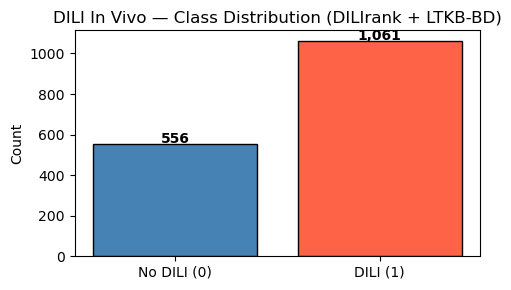

In [156]:
# ── Binary Labels ─────────────────────────────────────────────────────────────
#  TOXICITY = 1 -> DILI  |  TOXICITY = 0 -> No DILI
df['label'] = df['TOXICITY'].astype(int)

n_pos = (df['label'] == 1).sum()
n_neg = (df['label'] == 0).sum()
print(f'DILI     (1): {n_pos:,}')
print(f'No DILI  (0): {n_neg:,}')
print(f'Ratio       : {n_neg/n_pos:.1f}:1')

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(['No DILI (0)', 'DILI (1)'], [n_neg, n_pos],
              color=['steelblue', 'tomato'], edgecolor='black')
for b, v in zip(bars, [n_neg, n_pos]):
    ax.text(b.get_x() + b.get_width()/2, v + 3, f'{v:,}', ha='center', fontweight='bold')
ax.set_title('DILI In Vivo — Class Distribution (DILIrank + LTKB-BD)')
ax.set_ylabel('Count')
plt.tight_layout(); plt.savefig('class_dist.png', dpi=150); plt.show()

---
## Step 2 — Feature Engineering

### 2A. Morgan Fingerprints (ECFP4) — for Classical ML
### 2B. Rich Atom/Bond Graph Features — for GNN

In [157]:
# ── 5. Morgan ECFP4 (2048 bits) ──────────────────────────────────────────────
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps   = df['csmi'].apply(smiles_to_ecfp4)
valid = fps.notna()
df    = df[valid].reset_index(drop=True)
fps   = fps[valid]
X_fp  = np.vstack(fps.values)   # (N, 2048)
y_all = df['label'].values
print(f'Fingerprint matrix : {X_fp.shape}')
print(f'FP density         : {X_fp.mean():.4f}')

Fingerprint matrix : (1617, 2048)
FP density         : 0.0220


[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerator
[16:51:35] DEPRECATION WARNING: please use MorganGenerat

In [158]:
# ──  Rich Atom Features (27-dim) & Bond Features (6-dim) — for GNN ───────────
#
#  27 atom features
#    Atomic num one-hot (C,N,O,S,F,P,Cl,Br,I,other=10),
#    degree (0-5), formal charge, hybridization one-hot (SP/SP2/SP3/other=4),
#    is_aromatic, is_in_ring, total_Hs (0-4), normalised mass
#
#  6 bond features:
#    bond type one-hot (single/double/triple/aromatic=4),
#    is_conjugated, is_in_ring
#
ATOM_SYMBOLS = [6, 7, 8, 16, 9, 15, 17, 35, 53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0] * len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass
    return vec

from rdkit.Chem import rdchem
HYBRID_MAP = {
    rdchem.HybridizationType.SP  : 0,
    rdchem.HybridizationType.SP2 : 1,
    rdchem.HybridizationType.SP3 : 2,
}

def atom_feat(atom):
    at_oh  = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]  # 10-dim (+other)
    hyb    = [0, 0, 0, 0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1
    deg    = min(atom.GetDegree(), 5)
    deg_oh = [0]*6; deg_oh[deg] = 1
    fc     = atom.GetFormalCharge()
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0]
    extras = [
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        min(atom.GetTotalNumHs(), 4) / 4.0,
        atom.GetMass() / 100.0
    ]
    return at_oh + deg_oh + fc_enc + hyb + extras  # 10+6+3+4+4 = 27-dim

BOND_TYPES = [
    rdchem.BondType.SINGLE, rdchem.BondType.DOUBLE,
    rdchem.BondType.TRIPLE, rdchem.BondType.AROMATIC
]

def bond_feat(bond):
    bt = one_hot(bond.GetBondType(), BOND_TYPES)  # 4-dim
    return bt + [int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

ATOM_DIM = 27
BOND_DIM  = 6
print(f'Atom feature dim: {ATOM_DIM} | Bond feature dim: {BOND_DIM}')

Atom feature dim: 27 | Bond feature dim: 6


In [159]:
# ── 7. Build Graph Dataset ────────────────────────────────────────────────────
def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i, j], [j, i]]
        ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2, 0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    y = torch.tensor([label], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

graph_list = []
for smi, lbl in zip(df['csmi'].values, y_all):
    g = mol_to_graph(smi, lbl)
    if g: graph_list.append(g)

print(f'Graphs built: {len(graph_list):,}')
print(f'Example: {graph_list[0]}')

Graphs built: 1,617
Example: Data(x=[29, 27], edge_index=[2, 62], edge_attr=[62, 6], y=[1])


---
## Step 3 — 80/20/20 Split + Downsampling

In [160]:
# ── 8. 20% External Test Split ───────────────────────────────────────────────
X_pool, X_test, y_pool, y_test = train_test_split(
    X_fp, y_all, test_size=0.20, stratify=y_all, random_state=SEED)

# Parallel split for graph data (using same indices)
idx_all = np.arange(len(y_all))
idx_pool, idx_test = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)

graphs_pool = [graph_list[i] for i in idx_pool]
graphs_test = [graph_list[i] for i in idx_test]

print(f'Pool : {len(y_pool):,}  (pos={(y_pool==1).sum()}, neg={(y_pool==0).sum()})')
print(f'Test : {len(y_test):,}  (pos={(y_test==1).sum()}, neg={(y_test==0).sum()})')

Pool : 1,293  (pos=848, neg=445)
Test : 324  (pos=213, neg=111)


In [161]:
# ── Print Test Set Values ─────────────────────────────────────────────────────
df_test_view = df.iloc[idx_test].reset_index(drop=True).copy()
df_test_view['label'] = y_test

print(f'Test set size : {len(df_test_view):,} compounds')
print(f'X_test shape  : {X_test.shape}   (compounds x ECFP4 bits)')
print(f'y_test shape  : {y_test.shape}')
print(f'\nClass distribution:')
print(f'  DILI    (1): {(y_test == 1).sum():,}')
print(f'  No DILI (0): {(y_test == 0).sum():,}')

print(f'\n── First 20 test set compounds ──')
display(df_test_view[['csmi', 'label']].head(20))

print(f'\n── Fingerprint values (X_test) — first 5 rows, first 20 bits ──')
print(X_test[:5, :20])

print(f'\n── Labels (y_test) — first 20 values ──')
print(y_test[:20])

Test set size : 324 compounds
X_test shape  : (324, 2048)   (compounds x ECFP4 bits)
y_test shape  : (324,)

Class distribution:
  DILI    (1): 213
  No DILI (0): 111

── First 20 test set compounds ──


,csmi,label
0,C#CC1(O)CCC2C3CCC4=CC(=O)CCC4C3CCC21CC,1
1,CN1CCN(CCCN2c3ccccc3Sc3ccc(C(F)(F)F)cc32)CC1,0
2,O=C(O)c1cc(N=Nc2ccc(S(=O)(=O)Nc3ccccn3)cc2)ccc1O,1
3,CCC(C)C(=O)O[C@H]1C[C@H](O)C=C2C=C[C@H](C)[C@H...,1
4,OCC1OC(O)C(O)C(O)C1O.OCCOCC1OC(OCCO)C(OCCO)C(O...,0
5,CC(C)(C)c1ccc(C(=O)CCCN2CCC(OC(c3ccccc3)c3cccc...,1
6,CCCC=c1ncc(=CC(Cc2cccs2)C(=O)O)n1Cc1ccc(C(=O)O...,0
7,CCCCCCCCCCCC(CC1OC(=O)C1CCCCCC)OC(=O)C(CC(C)C)...,1
8,CCCCC1C(=O)N(c2ccccc2)N(c2ccc(O)cc2)C1=O,1
9,COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2,1



── Fingerprint values (X_test) — first 5 rows, first 20 bits ──
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]]

── Labels (y_test) — first 20 values ──
[1 0 1 1 0 1 0 1 1 1 0 1 0 1 1 1 1 1 1 1]


In [162]:
# ── 80/20 Train/Val Split from Pool ──────────────────────────────────────────
X_tr_raw, X_val, y_tr_raw, y_val = train_test_split(
    X_pool, y_pool, test_size=0.20, stratify=y_pool, random_state=SEED)

pool_sub_idx = np.arange(len(y_pool))
tr_sub_idx, val_sub_idx = train_test_split(
    pool_sub_idx, test_size=0.20, stratify=y_pool, random_state=SEED)

graphs_val   = [graphs_pool[i] for i in val_sub_idx]
graphs_trraw = [graphs_pool[i] for i in tr_sub_idx]

print(f'Train-raw: {len(y_tr_raw):,}  (pos={(y_tr_raw==1).sum()}, neg={(y_tr_raw==0).sum()})')
print(f'Val      : {len(y_val):,}  (pos={(y_val==1).sum()},  neg={(y_val==0).sum()})')

Train-raw: 1,034  (pos=678, neg=356)
Val      : 259  (pos=170,  neg=89)


In [163]:
# ──  Downsampling on TRAIN ONLY ───────────────────────────────────────────────
# Downsample the MAJORITY class to match the MINORITY class (whichever is larger)
pos_idx_tr = np.where(y_tr_raw == 1)[0]   # DILI
ina_idx_tr = np.where(y_tr_raw == 0)[0]   # No-DILI

rng = np.random.RandomState(SEED)

if len(pos_idx_tr) <= len(ina_idx_tr):
    # More No-DILI than DILI — downsample No-DILI (standard case)
    n_minority  = len(pos_idx_tr)
    sampled_ina = rng.choice(ina_idx_tr, size=n_minority, replace=False)
    train_idx   = np.concatenate([pos_idx_tr, sampled_ina])
else:
    # More DILI than No-DILI — downsample DILI
    n_minority  = len(ina_idx_tr)
    sampled_pos = rng.choice(pos_idx_tr, size=n_minority, replace=False)
    sampled_ina = ina_idx_tr  # keep all No-DILI for AD left-out tracking
    train_idx   = np.concatenate([sampled_pos, ina_idx_tr])

rng.shuffle(train_idx)

X_train      = X_tr_raw[train_idx]
y_train      = y_tr_raw[train_idx]
graphs_train = [graphs_trraw[i] for i in train_idx]

print(f'Balanced TRAIN: {len(y_train):,}  pos={(y_train==1).sum()} / neg={(y_train==0).sum()} (1:1)')
print(f'VAL  (real-world imbalance): {len(y_val):,}')
print(f'TEST (real-world imbalance): {len(y_test):,}')

Balanced TRAIN: 712  pos=356 / neg=356 (1:1)
VAL  (real-world imbalance): 259
TEST (real-world imbalance): 324


Split summary (% of total)
  Train:   712 (44.0%)  pos=356, neg=356
  Val  :   259 (16.0%)  pos=170, neg=89
  Test :   324 (20.0%)  pos=213, neg=111


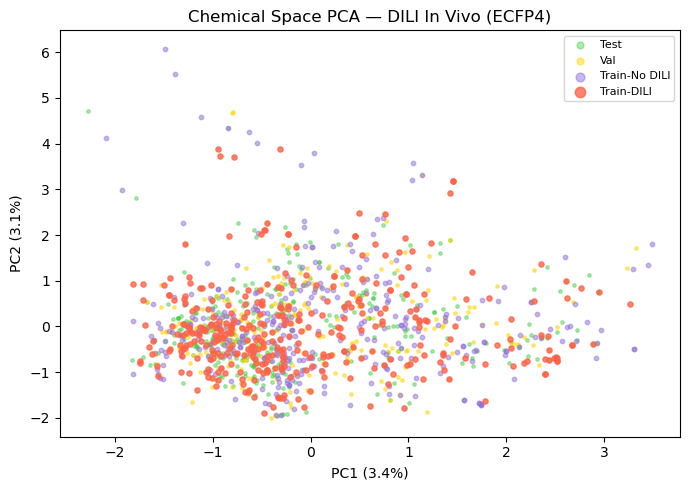

In [164]:
# ── 11. Split Summary & Chemical Space PCA ────────────────────────────────────
print('Split summary (% of total)')
for name, ys in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    print(f'  {name:5s}: {len(ys):5,} ({100*len(ys)/len(y_all):.1f}%)  '
          f'pos={(ys==1).sum()}, neg={(ys==0).sum()}')

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)
tr_p, va_p, te_p = pca.transform(X_train), pca.transform(X_val), pca.transform(X_test)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(te_p[:,0], te_p[:,1], c='limegreen',    s=6,  alpha=0.4, label='Test')
ax.scatter(va_p[:,0], va_p[:,1], c='gold',          s=6,  alpha=0.5, label='Val')
ax.scatter(tr_p[y_train==0,0], tr_p[y_train==0,1], c='mediumpurple', s=10, alpha=0.5, label='Train-No DILI')
ax.scatter(tr_p[y_train==1,0], tr_p[y_train==1,1], c='tomato',       s=14, alpha=0.8, label='Train-DILI')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Chemical Space PCA — DILI In Vivo (ECFP4)')
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.savefig('chem_space.png', dpi=150); plt.show()

Left-out No-DILI : 0
PC1: 3.4%  PC2: 3.1%  PC3: 2.4%
Total variance explained: 8.9%


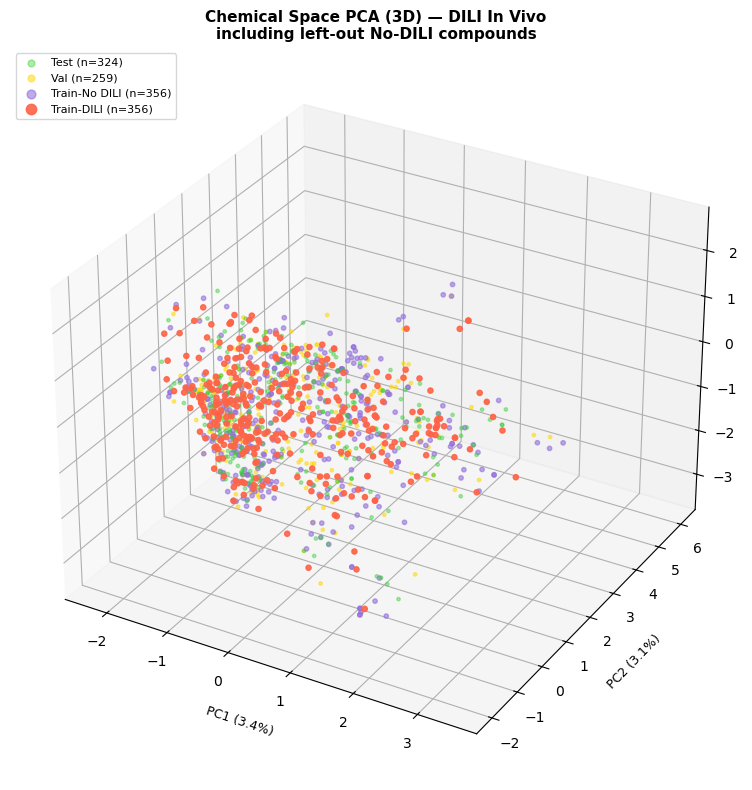

In [165]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# ── Find the left-out (discarded) compounds ───────────────────────────────────
# sampled_ina holds the indices of the kept minority-side compounds used in training
sampled_set    = set(sampled_ina.tolist())
leftout_idx_tr = np.array([idx for idx in ina_idx_tr if idx not in sampled_set],
                           dtype=int)  # force int dtype even if empty
X_leftout = X_tr_raw[leftout_idx_tr] if len(leftout_idx_tr) > 0 else np.empty((0, X_tr_raw.shape[1]))

print(f'Left-out No-DILI : {len(leftout_idx_tr):,}')

# ── 3-component PCA ───────────────────────────────────────────────────────────
pca3 = PCA(n_components=3, random_state=SEED)
pca3.fit(X_train)

tr_3 = pca3.transform(X_train)
va_3 = pca3.transform(X_val)
te_3 = pca3.transform(X_test)
lo_3 = pca3.transform(X_leftout) if len(X_leftout) > 0 else np.empty((0, 3))

pc1_var = pca3.explained_variance_ratio_[0]*100
pc2_var = pca3.explained_variance_ratio_[1]*100
pc3_var = pca3.explained_variance_ratio_[2]*100
print(f'PC1: {pc1_var:.1f}%  PC2: {pc2_var:.1f}%  PC3: {pc3_var:.1f}%')
print(f'Total variance explained: {pc1_var+pc2_var+pc3_var:.1f}%')

fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(111, projection='3d')

if len(lo_3) > 0:
    ax.scatter(lo_3[:,0], lo_3[:,1], lo_3[:,2],
               c='black', s=4, alpha=0.3, label=f'Left-out No-DILI (n={len(lo_3):,})')
ax.scatter(te_3[:,0], te_3[:,1], te_3[:,2],
           c='limegreen', s=6, alpha=0.4, label=f'Test (n={len(te_3):,})')
ax.scatter(va_3[:,0], va_3[:,1], va_3[:,2],
           c='gold', s=6, alpha=0.5, label=f'Val (n={len(va_3):,})')
ax.scatter(tr_3[y_train==0,0], tr_3[y_train==0,1], tr_3[y_train==0,2],
           c='mediumpurple', s=10, alpha=0.6, label=f'Train-No DILI (n={(y_train==0).sum():,})')
ax.scatter(tr_3[y_train==1,0], tr_3[y_train==1,1], tr_3[y_train==1,2],
           c='tomato', s=14, alpha=0.9, label=f'Train-DILI (n={(y_train==1).sum():,})')

ax.set_xlabel(f'PC1 ({pc1_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_ylabel(f'PC2 ({pc2_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_zlabel(f'PC3 ({pc3_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_title('Chemical Space PCA (3D) — DILI In Vivo\nincluding left-out No-DILI compounds',
             fontsize=11, fontweight='bold')
ax.legend(loc='upper left', fontsize=8, markerscale=2)
plt.tight_layout()
plt.savefig('chem_space_3d.png', dpi=150)
plt.show()

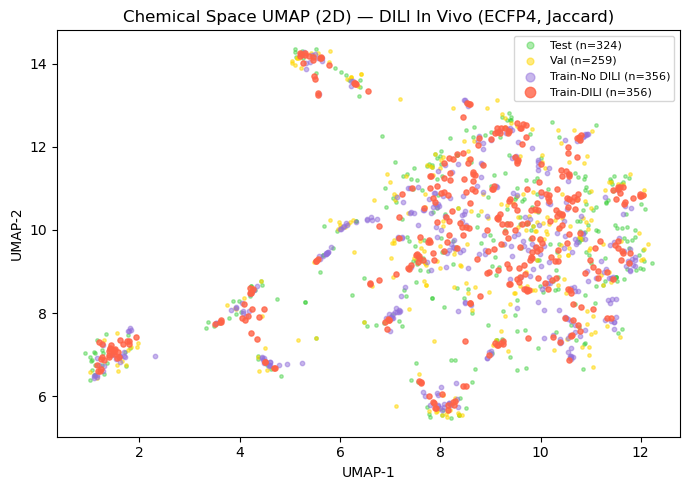

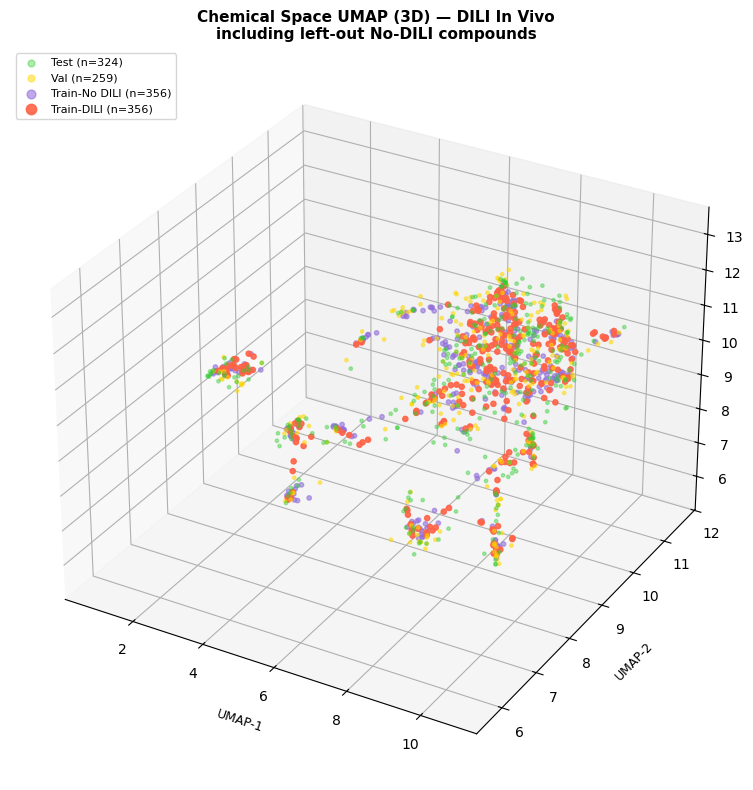

In [166]:
# ── 11b. Chemical Space UMAP ──────────────────────────────────────────────────
try:
    import umap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'umap-learn'])
    import umap

# ── 2D UMAP ───────────────────────────────────────────────────────────────────
reducer2 = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                     metric='jaccard', random_state=SEED)
reducer2.fit(X_train)

tr_u2 = reducer2.transform(X_train)
va_u2 = reducer2.transform(X_val)
te_u2 = reducer2.transform(X_test)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(te_u2[:,0], te_u2[:,1], c='limegreen',    s=6,  alpha=0.4, label=f'Test (n={len(te_u2):,})')
ax.scatter(va_u2[:,0], va_u2[:,1], c='gold',          s=6,  alpha=0.5, label=f'Val (n={len(va_u2):,})')
ax.scatter(tr_u2[y_train==0,0], tr_u2[y_train==0,1],
           c='mediumpurple', s=10, alpha=0.5, label=f'Train-No DILI (n={(y_train==0).sum():,})')
ax.scatter(tr_u2[y_train==1,0], tr_u2[y_train==1,1],
           c='tomato',       s=14, alpha=0.8, label=f'Train-DILI (n={(y_train==1).sum():,})')
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.set_title('Chemical Space UMAP (2D) — DILI In Vivo (ECFP4, Jaccard)')
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.savefig('chem_space_umap2d.png', dpi=150); plt.show()

# ── 3D UMAP (including left-out No-DILI) ─────────────────────────────────────
reducer3 = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1,
                     metric='jaccard', random_state=SEED)
reducer3.fit(X_train)

tr_u3 = reducer3.transform(X_train)
va_u3 = reducer3.transform(X_val)
te_u3 = reducer3.transform(X_test)
lo_u3 = reducer3.transform(X_leftout) if len(X_leftout) > 0 else np.empty((0, 3))

fig = plt.figure(figsize=(12, 8))
ax3 = fig.add_subplot(111, projection='3d')

if len(lo_u3) > 0:
    ax3.scatter(lo_u3[:,0], lo_u3[:,1], lo_u3[:,2],
                c='black', s=4, alpha=0.3, label=f'Left-out No-DILI (n={len(lo_u3):,})')
ax3.scatter(te_u3[:,0], te_u3[:,1], te_u3[:,2],
            c='limegreen',    s=6,  alpha=0.4, label=f'Test (n={len(te_u3):,})')
ax3.scatter(va_u3[:,0], va_u3[:,1], va_u3[:,2],
            c='gold',         s=6,  alpha=0.5, label=f'Val (n={len(va_u3):,})')
ax3.scatter(tr_u3[y_train==0,0], tr_u3[y_train==0,1], tr_u3[y_train==0,2],
            c='mediumpurple', s=10, alpha=0.6, label=f'Train-No DILI (n={(y_train==0).sum():,})')
ax3.scatter(tr_u3[y_train==1,0], tr_u3[y_train==1,1], tr_u3[y_train==1,2],
            c='tomato',       s=14, alpha=0.9, label=f'Train-DILI (n={(y_train==1).sum():,})')

ax3.set_xlabel('UMAP-1', fontsize=9, labelpad=8)
ax3.set_ylabel('UMAP-2', fontsize=9, labelpad=8)
ax3.set_zlabel('UMAP-3', fontsize=9, labelpad=8)
ax3.set_title('Chemical Space UMAP (3D) — DILI In Vivo\nincluding left-out No-DILI compounds',
              fontsize=11, fontweight='bold')
ax3.legend(loc='upper left', fontsize=8, markerscale=2)
plt.tight_layout(); plt.savefig('chem_space_umap3d.png', dpi=150); plt.show()

---
## Step 4 — Evaluation Helpers

In [167]:
# ── 12. Metrics Helper ────────────────────────────────────────────────────────
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn) > 0 else 0
    spec = tn/(tn+fp) if (tn+fp) > 0 else 0
    return {
        'Model'      : name,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100, 1),
        'Specificity': round(spec*100, 1),
        'CCR'        : round((sens+spec)/2*100, 1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob), 4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob), 4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred), 4),
        'Bal-Acc'    : round(balanced_accuracy_score(y_true, y_pred)*100, 1),
        'F1'         : round(f1_score(y_true, y_pred), 4),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
    }

METRIC_COLS = ['Model','CPT','Sensitivity','Specificity','CCR',
               'ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']
print('Helpers ready.')

Helpers ready.


---
## Step 5 — Classical ML: Hyperparameter Tuning on Validation Set

Train on balanced training set → tune on (imbalanced) validation set by **ROC-AUC** → final eval on test.

In [168]:
# ── 13. Random Forest Grid Search ────────────────────────────────────────────
rf_grid = ParameterGrid({
    'n_estimators'    : [300, 500],
    'max_features'    : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
    'max_depth'       : [None, 20]
})

best_rf_auc, best_rf, best_rf_params = 0, None, {}
print(f'RF: {len(rf_grid)} configs...')
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_rf_auc:
        best_rf_auc, best_rf, best_rf_params = auc, clf, p

print(f'Best RF  val AUC={best_rf_auc:.4f}  params={best_rf_params}')

RF: 16 configs...
Best RF  val AUC=0.7630  params={'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}


In [169]:
# ── 14. SVM Grid Search ───────────────────────────────────────────────────────
svm_grid = ParameterGrid({
    'C'    : [1, 10, 50],
    'gamma': ['scale', 0.01, 0.001]
})

best_svm_auc, best_svm, best_svm_params = 0, None, {}
print(f'SVM: {len(svm_grid)} configs...')
for p in svm_grid:
    clf = SVC(**p, kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_svm_auc:
        best_svm_auc, best_svm, best_svm_params = auc, clf, p

print(f'Best SVM val AUC={best_svm_auc:.4f}  params={best_svm_params}')

SVM: 9 configs...
Best SVM val AUC=0.7604  params={'C': 10, 'gamma': 'scale'}


In [170]:
# ── 15. XGBoost Grid Search ──────────────────────────────────────────────────
sw = (y_train==0).sum() / (y_train==1).sum()
xgb_grid = ParameterGrid({
    'n_estimators' : [300, 500],
    'max_depth'    : [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'subsample'    : [0.8],
    'colsample_bytree': [0.8]
})

best_xgb_auc, best_xgb, best_xgb_params = 0, None, {}
print(f'XGB: {len(xgb_grid)} configs...')
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_xgb_auc:
        best_xgb_auc, best_xgb, best_xgb_params = auc, clf, p

print(f'Best XGB val AUC={best_xgb_auc:.4f}  params={best_xgb_params}')

XGB: 12 configs...
Best XGB val AUC=0.7468  params={'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 500, 'subsample': 0.8}


In [171]:
# ── 16. Classical ML — Val & Test Evaluation ─────────────────────────────────
classical = {'Random Forest': best_rf, 'SVM': best_svm, 'XGBoost': best_xgb}
cl_probs_val  = {n: clf.predict_proba(X_val)[:,1]  for n, clf in classical.items()}
cl_probs_test = {n: clf.predict_proba(X_test)[:,1] for n, clf in classical.items()}

rows_val, rows_test = [], []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_val.append(evaluate(y_val,  cl_probs_val[name],  name, cpt))
        rows_test.append(evaluate(y_test, cl_probs_test[name], name, cpt))

df_cl_val  = pd.DataFrame(rows_val)[METRIC_COLS]
df_cl_test = pd.DataFrame(rows_test)[METRIC_COLS]

print('── Classical ML — Validation Set ──')
display(df_cl_val.set_index(['Model', 'CPT']))
print('\n── Classical ML — Test Set ──')
display(df_cl_test.set_index(['Model', 'CPT']))

── Classical ML — Validation Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         65.9         77.5  71.7   0.7630  0.8518  0.4124   
              0.8         10.0         97.8  53.9   0.7630  0.8518  0.1412   
SVM           0.5         67.6         68.5  68.1   0.7604  0.8601  0.3456   
              0.8          7.6         98.9  53.3   0.7604  0.8601  0.1370   
XGBoost       0.5         60.6         70.8  65.7   0.7468  0.8545  0.2980   
              0.8         43.5         89.9  66.7   0.7468  0.8545  0.3401   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     71.7  0.7417  
              0.8     53.9  0.1799  
SVM           0.5     68.1  0.7348  
              0.8     53.3  0.1413  
XGBoost       0.5     65.7  0.6890  
              0.8     66.7  0.5850


── Classical ML — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         66.2         65.8  66.0   0.7302  0.8303  0.3051   
              0.8         10.8         98.2  54.5   0.7302  0.8303  0.1600   
SVM           0.5         64.8         69.4  67.1   0.7224  0.8181  0.3248   
              0.8          8.5         99.1  53.8   0.7224  0.8181  0.1525   
XGBoost       0.5         62.9         68.5  65.7   0.6963  0.7840  0.2981   
              0.8         44.1         79.3  61.7   0.6963  0.7840  0.2313   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     66.0  0.7194  
              0.8     54.5  0.1933  
SVM           0.5     67.1  0.7169  
              0.8     53.8  0.1552  
XGBoost       0.5     65.7  0.7016  
              0.8     61.7  0.5697

---
## Step 6 — Graph Neural Networks (Classification)

**Architecture** (same for all 4 variants):
```
SMILES  Atoms+Bonds (27-dim / 6-dim)
  - Linear projection (hidden)
  - 3 x [Conv + BatchNorm1d + ReLU + Dropout + Residual]
  - GlobalMeanPool
  - MLP head [hidden->hidden/2->1]
  - BCEWithLogitsLoss
```
Variants: **GCN**, **GAT** (with bond-type attention), **GIN** (most expressive), **GraphSAGE**

In [172]:
# ── 17. GNN Architecture ─────────────────────────────────────────────────────
class MolGNN(nn.Module):
    """
     GNN for molecular binary classification.
     GCN, GAT, GIN, GraphSAGE via conv_type argument.
    3 conv layers with BatchNorm + Residual connections.
    """

    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4):
        super().__init__()
        self.conv_type = conv_type
        self.n_layers  = n_layers
        self.drop      = nn.Dropout(dropout)

        # Input projection
        self.proj = nn.Linear(in_dim, hidden)
        self.bn0  = nn.BatchNorm1d(hidden)

        # Conv layers + BatchNorm
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                self.convs.append(GATConv(hidden, hidden, heads=heads,
                                          concat=False, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(
                    nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden), nn.ReLU(),
                    nn.Linear(hidden, hidden)
                )
                self.convs.append(GINConv(mlp, train_eps=True))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))

        self.head = nn.Sequential(
            nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1)
        )

    def forward(self, x, edge_index, batch):
        x = F.relu(self.bn0(self.proj(x)))
        for conv, bn in zip(self.convs, self.bns):
            residual = x
            x = conv(x, edge_index)
            x = bn(x)
            x = F.relu(x)
            x = self.drop(x)
            x = x + residual  # residual connection
        x = global_mean_pool(x, batch)
        return self.head(x).squeeze(-1)

In [173]:
# ── 18. Training & Evaluation Functions ──────────────────────────────────────
def gnn_train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        loss   = criterion(logits, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)

@torch.no_grad()
def gnn_eval(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        batch = batch.to(device)
        all_logits.append(model(batch.x, batch.edge_index, batch.batch).cpu())
        all_labels.append(batch.y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    probs  = torch.sigmoid(torch.tensor(logits)).numpy()
    auc    = roc_auc_score(labels, probs)
    return probs, labels, auc

print('Training helpers defined.')

Training helpers defined.


In [174]:
# ── 19. GNN DataLoaders ───────────────────────────────────────────────────────
BATCH = 64
train_loader = DataLoader(graphs_train, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(graphs_val,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(graphs_test,  batch_size=BATCH, shuffle=False)

# Positive weight for BCEWithLogitsLoss — upweights DILI class in GNN training
# (training set is balanced 1:1, so pos_weight=1)
pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()], device=DEVICE)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f'Train graphs: {len(graphs_train)}')
print(f'Val   graphs: {len(graphs_val)}')
print(f'Test  graphs: {len(graphs_test)}')
print(f'pos_weight   : {pos_weight.item():.3f} (1.0 = balanced)')

Train graphs: 712
Val   graphs: 259
Test  graphs: 324
pos_weight   : 1.000 (1.0 = balanced)


In [175]:
# ── 20. Hyperparameter Grid & Training Loop ───────────────────────────────────
GNN_CONFIGS = {
    'GCN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'GAT' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
        {'hidden':128, 'n_layers':3, 'dropout':0.4, 'lr':0.0005, 'heads':8},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
    ],
    'GIN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'SAGE': [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
}

MAX_EPOCHS = 100
PATIENCE   = 20   # early stopping

gnn_best_models  = {}
gnn_best_configs = {}
gnn_best_val_auc = {}
gnn_history      = {}

for arch, configs in GNN_CONFIGS.items():
    print(f'\n{"="*55}')
    print(f'Architecture: {arch}  ({len(configs)} configs)')
    best_auc, best_state, best_cfg = 0, None, {}

    for cfg in configs:
        heads = cfg.pop('heads', 4)
        model = MolGNN(
            ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
            dropout=cfg['dropout'], conv_type=arch, heads=heads
        ).to(DEVICE)
        cfg['heads'] = heads

        optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='max', factor=0.5, patience=10)

        tr_losses, va_aucs = [], []
        best_val_auc_cfg, best_state_cfg = 0, None
        no_improve = 0

        for epoch in range(MAX_EPOCHS):
            tr_loss = gnn_train_epoch(model, train_loader, optimizer, criterion, DEVICE)
            _, _, va_auc = gnn_eval(model, val_loader, DEVICE)
            scheduler.step(va_auc)
            tr_losses.append(tr_loss)
            va_aucs.append(va_auc)
            if va_auc > best_val_auc_cfg:
                best_val_auc_cfg = va_auc
                best_state_cfg = copy.deepcopy(model.state_dict())
                no_improve = 0
            else:
                no_improve += 1
            if no_improve >= PATIENCE:
                break

        print(f'  cfg={cfg}  val_AUC={best_val_auc_cfg:.4f}  epochs={epoch+1}')
        if best_val_auc_cfg > best_auc:
            best_auc, best_state, best_cfg = best_val_auc_cfg, best_state_cfg, cfg
            best_history = (tr_losses, va_aucs)

    gnn_best_models[arch]  = best_state
    gnn_best_configs[arch] = best_cfg
    gnn_best_val_auc[arch] = best_auc
    gnn_history[arch]      = best_history
    print(f'-> Best {arch} val AUC={best_auc:.4f}  cfg={best_cfg}')


Architecture: GCN  (3 configs)
  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val_AUC=0.6959  epochs=71
  cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val_AUC=0.7132  epochs=62
  cfg={'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  val_AUC=0.7265  epochs=86
-> Best GCN val AUC=0.7265  cfg={'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}

Architecture: GAT  (3 configs)
  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val_AUC=0.6996  epochs=28
  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  val_AUC=0.7283  epochs=82
  cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val_AUC=0.7304  epochs=35
-> Best GAT val AUC=0.7304  cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}

Architecture: GIN  (3 configs)
  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.00

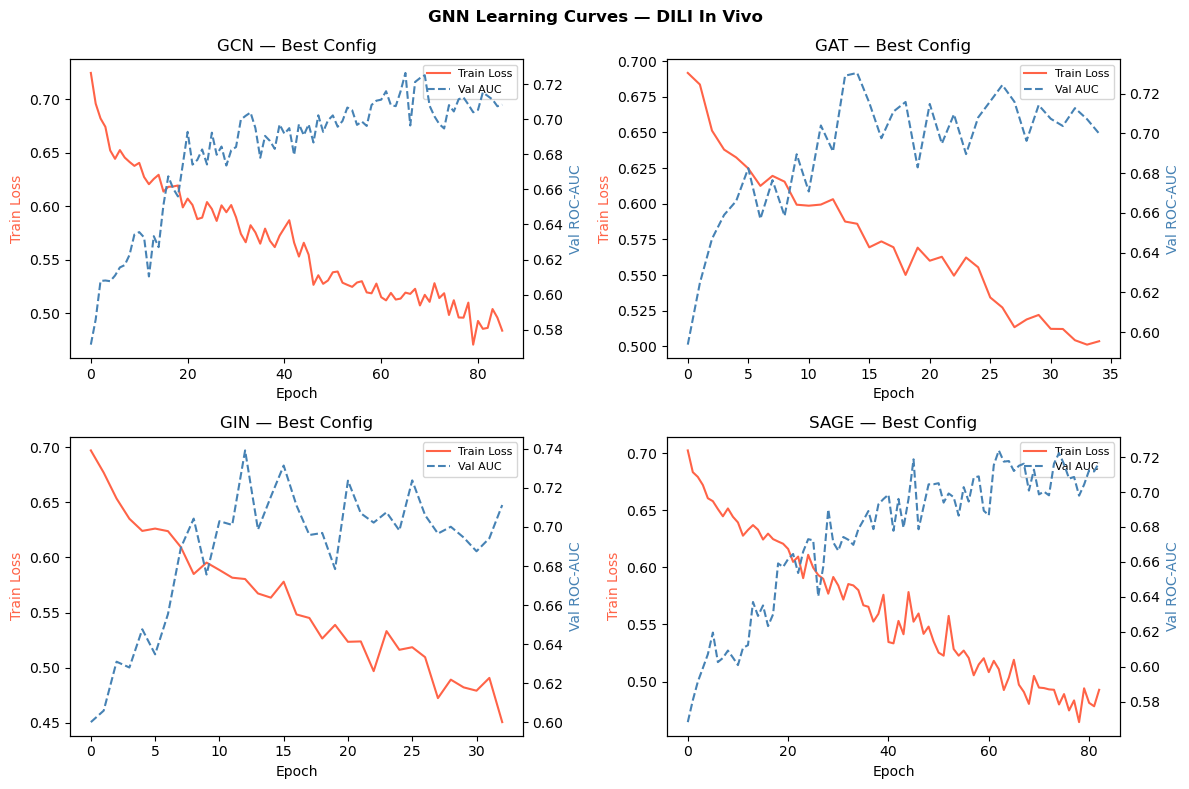

In [176]:
# ── 21. Learning Curves ───────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.flat, ['GCN', 'GAT', 'GIN', 'SAGE']):
    tr_losses, va_aucs = gnn_history[arch]
    ax2 = ax.twinx()
    ax.plot(tr_losses, color='tomato',    label='Train Loss')
    ax2.plot(va_aucs,  color='steelblue', label='Val AUC', linestyle='--')
    ax.set_title(f'{arch} — Best Config')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Train Loss', color='tomato')
    ax2.set_ylabel('Val ROC-AUC', color='steelblue')
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1+lines2, labels1+labels2, fontsize=8)
plt.suptitle('GNN Learning Curves — DILI In Vivo', fontweight='bold')
plt.tight_layout(); plt.savefig('gnn_learning_curves.png', dpi=150); plt.show()

In [177]:
# ── 22. GNN Test Evaluation ───────────────────────────────────────────────────
gnn_probs_test = {}

for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads',4)).to(DEVICE)
    model.load_state_dict(state)
    probs, _, _ = gnn_eval(model, test_loader, DEVICE)
    gnn_probs_test[arch] = probs

rows_gnn = []
for arch, prob in gnn_probs_test.items():
    for cpt in [0.5, 0.8]:
        rows_gnn.append(evaluate(y_test, prob, arch, cpt))

df_gnn_test = pd.DataFrame(rows_gnn)[METRIC_COLS]
print('── GNN — Test Set ──')
display(df_gnn_test.set_index(['Model', 'CPT']))

── GNN — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         52.6         68.5  60.5   0.6348  0.7578  0.2007     60.5   
      0.8         13.1         93.7  53.4   0.6348  0.7578  0.1046     53.4   
GAT   0.5         54.5         66.7  60.6   0.6651  0.8072  0.2008     60.6   
      0.8          3.8         99.1  51.4   0.6651  0.8072  0.0824     51.4   
GIN   0.5         65.7         55.9  60.8   0.6353  0.7369  0.2078     60.8   
      0.8         10.8         93.7  52.2   0.6353  0.7369  0.0735     52.2   
SAGE  0.5         62.4         61.3  61.9   0.6713  0.7984  0.2258     61.9   
      0.8         22.1         92.8  57.4   0.6713  0.7984  0.1878     57.4   

               F1  
Model CPT          
GCN   0.5  0.6222  
      0.8  0.2258  
GAT   0.5  0.6339  
      0.8  0.0721  
GIN   0.5  0.6965  
      0.8  0.1893  
SAGE  0.5  0.6838  
      0.8  0.3507

---
## Step 7 — Consensus Model (All Classical + GNN)

In [178]:
# ── 23. Consensus: Average All Model Probabilities ────────────────────────────
all_test_probs = {**cl_probs_test, **gnn_probs_test}

consensus_prob = np.mean(list(all_test_probs.values()), axis=0)
all_test_probs['Consensus'] = consensus_prob

cl_consensus  = np.mean(list(cl_probs_test.values()), axis=0)
all_test_probs['Consensus-Classical'] = cl_consensus

gnn_consensus = np.mean(list(gnn_probs_test.values()), axis=0)
all_test_probs['Consensus-GNN'] = gnn_consensus

final_rows = []
for name, prob in all_test_probs.items():
    for cpt in [0.5, 0.8]:
        final_rows.append(evaluate(y_test, prob, name, cpt))

df_final = pd.DataFrame(final_rows)[METRIC_COLS]
print('── FULL TEST SET COMPARISON ──')
display(df_final.set_index(['Model', 'CPT']))

── FULL TEST SET COMPARISON ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC  \
Model               CPT                                                    
Random Forest       0.5         66.2         65.8  66.0   0.7302  0.8303   
                    0.8         10.8         98.2  54.5   0.7302  0.8303   
SVM                 0.5         64.8         69.4  67.1   0.7224  0.8181   
                    0.8          8.5         99.1  53.8   0.7224  0.8181   
XGBoost             0.5         62.9         68.5  65.7   0.6963  0.7840   
                    0.8         44.1         79.3  61.7   0.6963  0.7840   
GCN                 0.5         52.6         68.5  60.5   0.6348  0.7578   
                    0.8         13.1         93.7  53.4   0.6348  0.7578   
GAT                 0.5         54.5         66.7  60.6   0.6651  0.8072   
                    0.8          3.8         99.1  51.4   0.6651  0.8072   
GIN                 0.5         65.7         55.9  60.8   0.6353  0.7369   
                    0.8         10.8         93.7  52.2   0.6353  0.7369   
SAGE                0.5         62.4         61.3  61.9   0.6713  0.7984   
                    0.8         22.1         92.8  57.4   0.6713  0.7984   
Consensus           0.5         62.9         70.3  66.6   0.7079  0.8185   
                    0.8          8.5         98.2  53.3   0.7079  0.8185   
Consensus-Classical 0.5         64.3         68.5  66.4   0.7202  0.8242   
                    0.8         20.7         94.6  57.6   0.7202  0.8242   
Consensus-GNN       0.5         59.6         61.3  60.4   0.6634  0.7906   
                    0.8         11.3         97.3  54.3   0.6634  0.7906   

                            MCC  Bal-Acc      F1  
Model               CPT                           
Random Forest       0.5  0.3051     66.0  0.7194  
                    0.8  0.1600     54.5  0.1933  
SVM                 0.5  0.3248     67.1  0.7169  
                    0.8  0.1525     53.8  0.1552  
XGBoost             0.5  0.2981     65.7  0.7016  
                    0.8  0.2313     61.7  0.5697  
GCN                 0.5  0.2007     60.5  0.6222  
                    0.8  0.1046     53.4  0.2258  
GAT                 0.5  0.2008     60.6  0.6339  
                    0.8  0.0824     51.4  0.0721  
GIN                 0.5  0.2078     60.8  0.6965  
                    0.8  0.0735     52.2  0.1893  
SAGE                0.5  0.2258     61.9  0.6838  
                    0.8  0.1878     57.4  0.3507  
Consensus           0.5  0.3151     66.6  0.7053  
                    0.8  0.1311     53.3  0.1545  
Consensus-Classical 0.5  0.3118     66.4  0.7117  
                    0.8  0.2004     57.6  0.3346  
Consensus-GNN       0.5  0.1985     60.4  0.6632  
                    0.8  0.1471     54.3  0.2000

---
## Step 8 — Applicability Domain

AD threshold  : 0.6633
Test in AD    : 142/324 (43.8%)
  AD-filtered Sensitivity: 67.9
  AD-filtered Specificity: 72.4
  AD-filtered CCR: 70.1
  AD-filtered ROC-AUC: 0.7601
  AD-filtered MCC: 0.3961


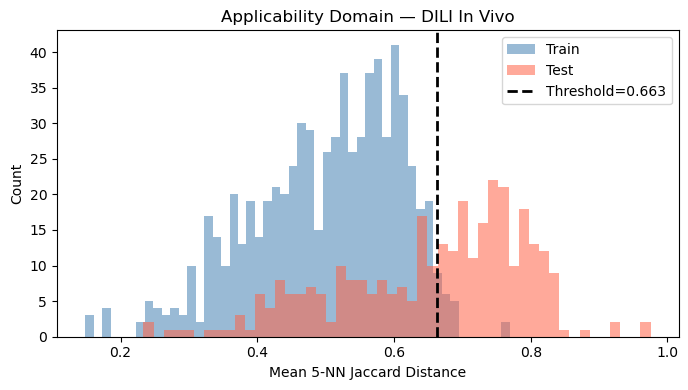

In [179]:
# ── 24. AD — k-NN Jaccard ─────────────────────────────────────────────────────
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(X_train)
d_tr, _ = nn_ad.kneighbors(X_train)
md_tr   = d_tr.mean(axis=1)
ad_thr  = md_tr.mean() + 1.5*md_tr.std()

d_te, _ = nn_ad.kneighbors(X_test)
md_te   = d_te.mean(axis=1)
in_ad   = md_te <= ad_thr
cov     = in_ad.mean()*100

print(f'AD threshold  : {ad_thr:.4f}')
print(f'Test in AD    : {in_ad.sum()}/{len(y_test)} ({cov:.1f}%)')

if in_ad.sum() >= 20:
    m = evaluate(y_test[in_ad], consensus_prob[in_ad], 'Consensus AD', cpt=0.5)
    for k in ['Sensitivity','Specificity','CCR','ROC-AUC','MCC']:
        print(f'  AD-filtered {k}: {m[k]}')

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(md_tr, bins=50, alpha=0.55, color='steelblue', label='Train')
ax.hist(md_te, bins=50, alpha=0.55, color='tomato',    label='Test')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2,
           label=f'Threshold={ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance'); ax.set_ylabel('Count')
ax.set_title('Applicability Domain — DILI In Vivo'); ax.legend()
plt.tight_layout(); plt.savefig('ad_dist.png',dpi=150); plt.show()

---
## Step 9 — Final Summary

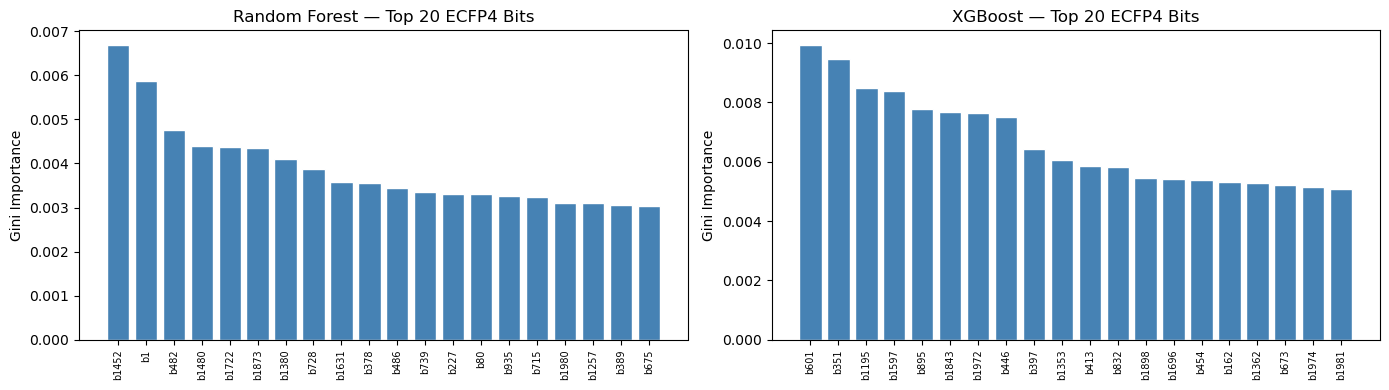

In [180]:
# ── 25. Feature Importance — RF & XGBoost ────────────────────────────────────
fig, axes = plt.subplots(1,2,figsize=(14,4))
for ax,(name,clf) in zip(axes,[('Random Forest',best_rf),('XGBoost',best_xgb)]):
    imp = clf.feature_importances_
    top = np.argsort(imp)[::-1][:20]
    ax.bar(range(20), imp[top], color='steelblue', edgecolor='white')
    ax.set_xticks(range(20))
    ax.set_xticklabels([f'b{i}' for i in top], rotation=90, fontsize=7)
    ax.set_title(f'{name} — Top 20 ECFP4 Bits'); ax.set_ylabel('Gini Importance')
plt.tight_layout(); plt.savefig('feat_importance.png',dpi=150); plt.show()

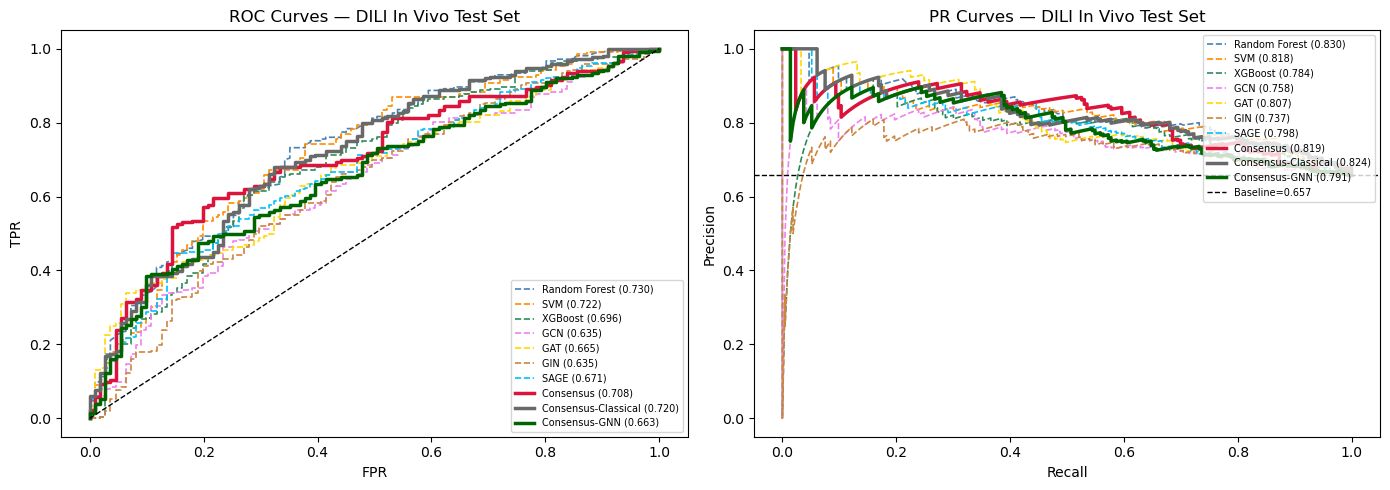

In [181]:
# ── 26. ROC Curves — All Models ──────────────────────────────────────────────
COLORS = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
          'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
          'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1,2,figsize=(14,5))
for name, prob in all_test_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS.get(name,'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr,tpr,_ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr,tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre,rec,_ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    axes[1].plot(rec,pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — DILI In Vivo Test Set'); axes[0].legend(fontsize=7,loc='lower right')

axes[1].axhline(y_test.mean(),color='k',ls='--',lw=1,label=f'Baseline={y_test.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — DILI In Vivo Test Set'); axes[1].legend(fontsize=7,loc='upper right')

plt.tight_layout(); plt.savefig('roc_pr_all.png',dpi=150); plt.show()

In [182]:
# ── 27. Ranked Summary Table (CPT-1) ─────────────────────────────────────────
summary_cpt1 = df_final[df_final['CPT']==0.5].drop(columns='CPT').set_index('Model')
summary_sorted = summary_cpt1.sort_values('ROC-AUC', ascending=False)
print('='*90)
print('FINAL RANKING — DILI In Vivo Binary (CPT-1, threshold>=0.50)')
print('DILIrank Gold Standard + LTKB-BD | 80/20/20 split | Hao Zhu downsampling | Morgan ECFP4 + GNN atom/bond features')
print('='*90)
display(summary_sorted)

print(f'\nApplicability Domain coverage: {cov:.1f}%')
summary_sorted.to_csv('qsar_dili_invivo_results.csv')
print('Saved -> qsar_dili_invivo_results.csv')

FINAL RANKING — DILI In Vivo Binary (CPT-1, threshold>=0.50)
DILIrank Gold Standard + LTKB-BD | 80/20/20 split | Hao Zhu downsampling | Morgan ECFP4 + GNN atom/bond features


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
Random Forest,66.2,65.8,66.0,0.7302,0.8303,0.3051,66.0,0.7194
SVM,64.8,69.4,67.1,0.7224,0.8181,0.3248,67.1,0.7169
Consensus-Classical,64.3,68.5,66.4,0.7202,0.8242,0.3118,66.4,0.7117
Consensus,62.9,70.3,66.6,0.7079,0.8185,0.3151,66.6,0.7053
XGBoost,62.9,68.5,65.7,0.6963,0.7840,0.2981,65.7,0.7016
SAGE,62.4,61.3,61.9,0.6713,0.7984,0.2258,61.9,0.6838
GAT,54.5,66.7,60.6,0.6651,0.8072,0.2008,60.6,0.6339
Consensus-GNN,59.6,61.3,60.4,0.6634,0.7906,0.1985,60.4,0.6632
GIN,65.7,55.9,60.8,0.6353,0.7369,0.2078,60.8,0.6965



Applicability Domain coverage: 43.8%
Saved -> qsar_dili_invivo_results.csv


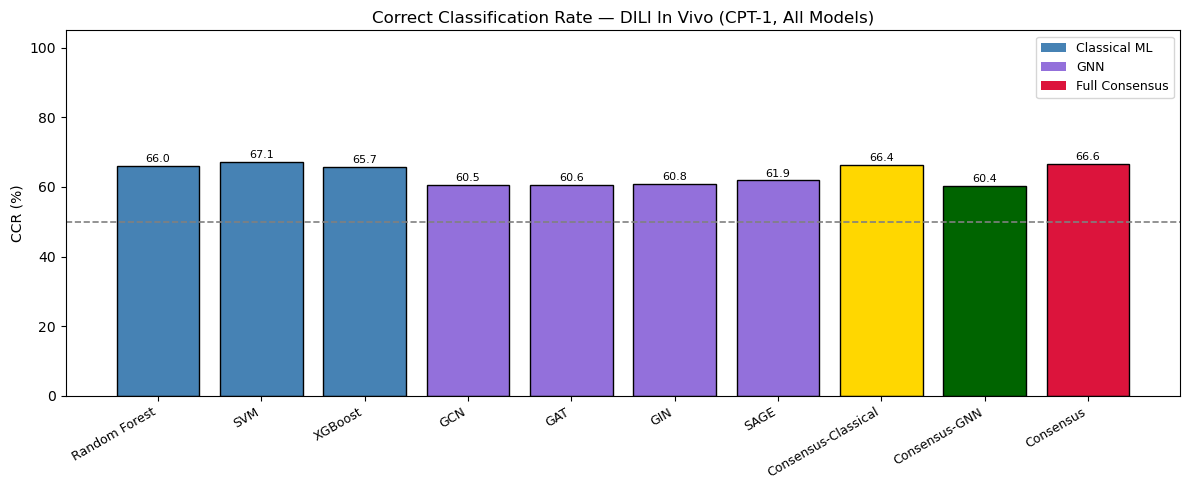

In [183]:
# ── 28. CCR Comparison Bar Chart ─────────────────────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals = [summary_cpt1.loc[m,'CCR'] if m in summary_cpt1.index else 0 for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12,5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0,105)
ax.set_title('Correct Classification Rate — DILI In Vivo (CPT-1, All Models)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
ax.legend()
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus')]
ax.legend(handles=legend_elements, fontsize=9)
plt.tight_layout(); plt.savefig('ccr_all_models.png',dpi=150); plt.show()

Best model (ROC-AUC): Random Forest
              precision    recall  f1-score   support

  No DILI(0)       0.50      0.66      0.57       111
     DILI(1)       0.79      0.66      0.72       213

    accuracy                           0.66       324
   macro avg       0.65      0.66      0.64       324
weighted avg       0.69      0.66      0.67       324



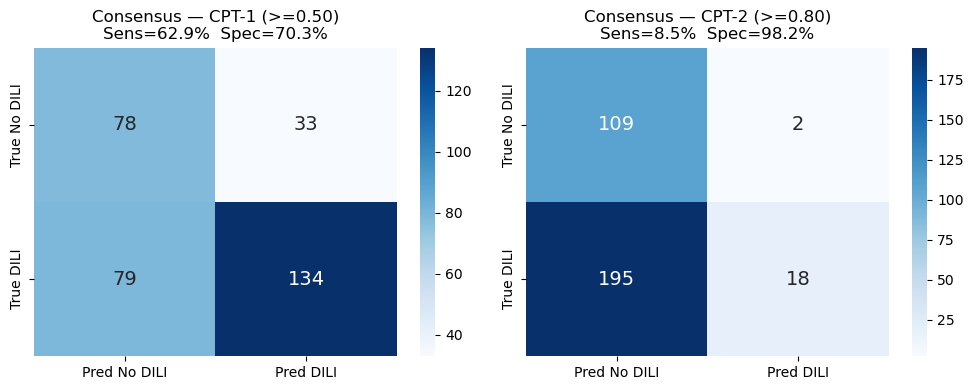

In [184]:
# ── 29. Best Model Report ─────────────────────────────────────────────────────
best_name = summary_sorted.index[0]
best_prob = all_test_probs[best_name]
best_pred = (best_prob >= 0.5).astype(int)
print(f'Best model (ROC-AUC): {best_name}')
print(classification_report(y_test, best_pred, target_names=['No DILI(0)','DILI(1)']))

# Confusion matrix
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, cpt, label in zip(axes,[0.5,0.8],['CPT-1 (>=0.50)','CPT-2 (>=0.80)']):
    pred = (consensus_prob >= cpt).astype(int)
    cm   = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred No DILI','Pred DILI'],
                yticklabels=['True No DILI','True DILI'], annot_kws={'size':14})
    tn,fp,fn,tp = cm.ravel()
    sens = tp/(tp+fn); spec = tn/(tn+fp)
    ax.set_title(f'Consensus — {label}\nSens={sens*100:.1f}%  Spec={spec*100:.1f}%')
plt.tight_layout(); plt.savefig('confusion_final.png',dpi=150); plt.show()

---
## Step 10 — Single Compound Prediction

Paste any SMILES below to run it through all 7 trained models and get a consensus DILI prediction.

In [185]:
# ── 30. Single Compound Prediction ───────────────────────────────────────────
# Change TEST_SMILES to any molecule you want to predict.
# Set TRUE_LABEL = 1 (DILI) or 0 (No DILI) if known, else None.

from rdkit.Chem import Descriptors

TEST_SMILES  = "C1=CC=C(C=C1)C(=O)C2=CC=CC=C2O"  
TRUE_LABEL   = None                       

# Step A: Parse & canonicalise
mol = Chem.MolFromSmiles(TEST_SMILES)
if mol is None:
    raise ValueError(f'RDKit could not parse SMILES: {TEST_SMILES!r} — check for typos.')

canon = Chem.MolToSmiles(mol)
mw    = Descriptors.MolWt(mol)
print(f'Compound : {TEST_SMILES}')
print(f'Canonical: {canon}')
print(f'Mol. Weight: {mw:.2f} Da  |  Atoms: {mol.GetNumAtoms()}')

# Step B: Morgan fingerprint (for classical ML + AD)
fp_arr  = smiles_to_ecfp4(canon)
X_query = fp_arr.reshape(1, -1)

# Step C: Build graph (for GNN)
graph_query  = mol_to_graph(canon, label=0)
query_loader = DataLoader([graph_query], batch_size=1, shuffle=False)

# Step D: Classical ML probabilities
cl_query_probs = {}
for name, clf in classical.items():
    cl_query_probs[name] = float(clf.predict_proba(X_query)[0, 1])

# Step E: GNN probabilities
gnn_query_probs = {}
for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads',4)).to(DEVICE)
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        batch = next(iter(query_loader)).to(DEVICE)
        logit = model(batch.x, batch.edge_index, batch.batch)
        gnn_query_probs[arch] = float(torch.sigmoid(logit).cpu())

# Step F: Consensus
all_query_probs = {**cl_query_probs, **gnn_query_probs}
consensus_q     = np.mean(list(all_query_probs.values()))

# Step G: Applicability Domain
d_q, _ = nn_ad.kneighbors(X_query)
md_q   = d_q.mean()
in_ad_q = md_q <= ad_thr

# Report
print('\n' + '='*55)
print('         DILI IN VIVO PREDICTION REPORT')
print('='*55)
for name, p in all_query_probs.items():
    tag = 'DILI' if p >= 0.5 else 'No DILI'
    print(f'  {name:20s}: {p:.3f}  -> {tag}')
print('-'*55)
cons_tag = 'DILI' if consensus_q >= 0.5 else 'No DILI'
print(f'  {"CONSENSUS":20s}: {consensus_q:.3f}  -> {cons_tag}')
print(f'  AD distance        : {md_q:.4f}  (threshold={ad_thr:.4f})')
print(f'  In Applicability Domain: {"YES" if in_ad_q else "NO — prediction less reliable"}')
if TRUE_LABEL is not None:
    correct = (consensus_q >= 0.5) == bool(TRUE_LABEL)
    print(f'  True label: {TRUE_LABEL}  |  Consensus correct: {correct}')
print('='*55)

Compound : C1=CC=C(C=C1)C(=O)C2=CC=CC=C2O
Canonical: O=C(c1ccccc1)c1ccccc1O
Mol. Weight: 198.22 Da  |  Atoms: 15

         DILI IN VIVO PREDICTION REPORT
  Random Forest       : 0.550  -> DILI
  SVM                 : 0.500  -> DILI
  XGBoost             : 0.108  -> No DILI
  GCN                 : 0.743  -> DILI
  GAT                 : 0.654  -> DILI
  GIN                 : 0.635  -> DILI
  SAGE                : 0.706  -> DILI
-------------------------------------------------------
  CONSENSUS           : 0.557  -> DILI
  AD distance        : 0.7058  (threshold=0.6633)
  In Applicability Domain: NO — prediction less reliable


[16:55:18] DEPRECATION WARNING: please use MorganGenerator


---
## Step 11 — Fragment Attribution: Which Substructures Drive DILI Predictions?

Same approach as the mito notebook — inspect what the model learned, then compare with mito results.

- **11a. XGBoost top ECFP4 bits** → draw the substructure each bit encodes
- **11b. GNN gradient saliency** → colour each atom by contribution to the prediction
- **11c. Cross-comparison** → which bits appear in BOTH mito and DILI models? Those are mito-mediated DILI fragments.

Top 10 ECFP4 bits driving XGBoost DILI predictions:
  Rank  1  bit= 601  importance=0.0099
  Rank  2  bit= 351  importance=0.0095
  Rank  3  bit=1195  importance=0.0085
  Rank  4  bit=1597  importance=0.0084
  Rank  5  bit= 895  importance=0.0078
  Rank  6  bit=1843  importance=0.0077
  Rank  7  bit=1972  importance=0.0076
  Rank  8  bit= 446  importance=0.0075
  Rank  9  bit= 397  importance=0.0064
  Rank 10  bit=1353  importance=0.0060


[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerator
[11:00:48] DEPRECATION WARNING: please use MorganGenerat

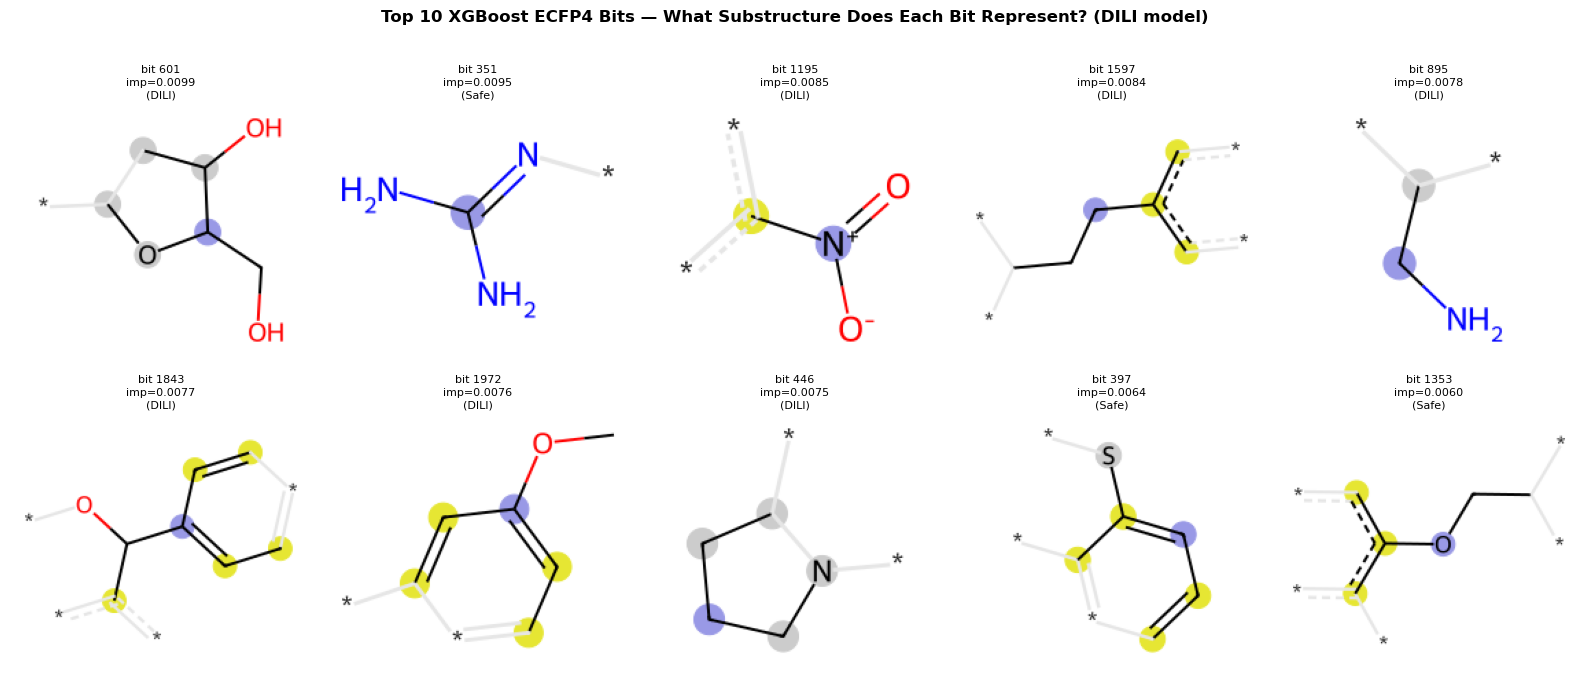

Saved → fragment_attribution_dili_xgb.png


In [189]:
# ── 31. Fragment Attribution A: XGBoost Top ECFP4 Bits → Actual Substructures ──
from rdkit.Chem import Draw, AllChem
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# 1. Top 10 bits from XGBoost Gini importance
imp      = best_xgb.feature_importances_
top_bits = np.argsort(imp)[::-1][:10]

print("Top 10 ECFP4 bits driving XGBoost DILI predictions:")
for rank, bit in enumerate(top_bits):
    print(f"  Rank {rank+1:2d}  bit={bit:4d}  importance={imp[bit]:.4f}")

# 2. For each top bit find a test molecule that has it set and draw the fragment
smiles_list = df_test_view['csmi'].astype(str).tolist()
labels_list = y_test.tolist()

imgs, captions = [], []
for bit in top_bits:
    for smi, lbl in zip(smiles_list, labels_list):
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        bit_info = {}
        AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048, bitInfo=bit_info)
        if bit in bit_info:
            img = Draw.DrawMorganBit(mol, bit, bit_info, molSize=(220, 180))
            imgs.append(img)
            captions.append(f"bit {bit}\nimp={imp[bit]:.4f}\n({'DILI' if lbl==1 else 'Safe'})")
            break
    else:
        imgs.append(Image.new('RGB', (220, 180), color=(240, 240, 240)))
        captions.append(f"bit {bit}\nimp={imp[bit]:.4f}\n(not in test set)")

# 3. Plot 2×5 grid
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
fig.suptitle("Top 10 XGBoost ECFP4 Bits — What Substructure Does Each Bit Represent? (DILI model)",
             fontsize=12, fontweight='bold', y=1.01)
for ax, img, cap in zip(axes.flat, imgs, captions):
    ax.imshow(img)
    ax.set_title(cap, fontsize=8, linespacing=1.4)
    ax.axis('off')
plt.tight_layout()
plt.savefig('fragment_attribution_dili_xgb.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved → fragment_attribution_dili_xgb.png")

Explaining: GAT


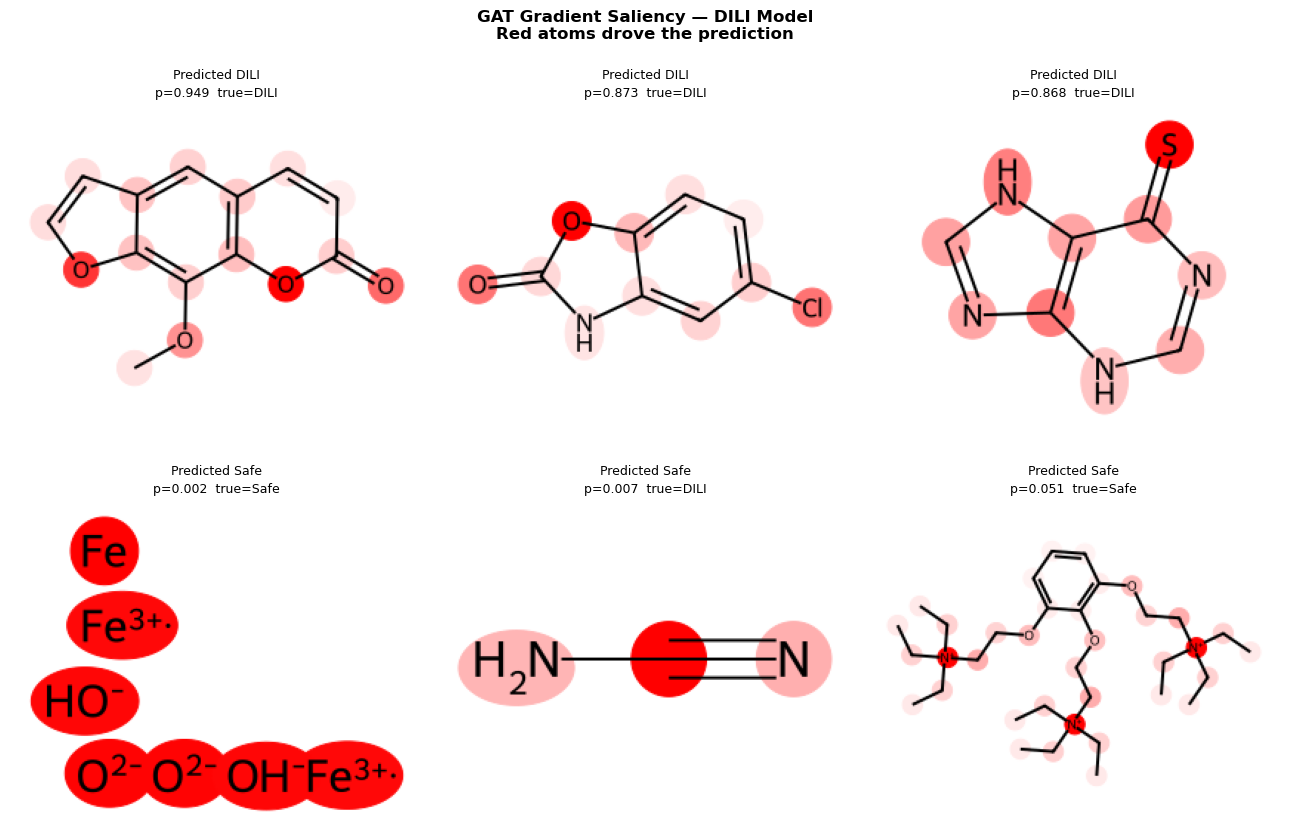

Saved → fragment_saliency_dili_gnn.png


In [190]:
# ── 32. Fragment Attribution B: GNN Gradient Saliency on DILI Model ────────
import torch
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import numpy as np

# Load best GNN
arch_order    = ['GAT', 'GIN', 'SAGE', 'GCN']
best_arch     = next((a for a in arch_order if a in gnn_best_models), list(gnn_best_models.keys())[0])
cfg           = gnn_best_configs[best_arch]
explain_model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                        dropout=0.0, conv_type=best_arch,
                        heads=cfg.get('heads', 4)).to(DEVICE)
explain_model.load_state_dict(gnn_best_models[best_arch])
explain_model.eval()
print(f"Explaining: {best_arch}")

def gradient_saliency(model, pyg_data, device):
    data  = pyg_data.to(device)
    x     = data.x.clone().detach().requires_grad_(True)
    batch = torch.zeros(x.size(0), dtype=torch.long, device=device)
    logit = model(x, data.edge_index, batch)
    logit.backward()
    return x.grad.abs().sum(dim=1).cpu().numpy()

def draw_mol_saliency(smi, saliency, size=(280, 220)):
    mol = Chem.MolFromSmiles(str(smi))
    if mol is None:
        return Image.new('RGB', size, (220, 220, 220))
    sal = np.array(saliency, dtype=float)
    if sal.max() > 0:
        sal = sal / sal.max()
    atom_colors = {i: (1.0, 1.0 - float(v), 1.0 - float(v)) for i, v in enumerate(sal)}
    highlight_r = {i: 0.45 for i in range(mol.GetNumAtoms())}
    try:
        drawer = rdMolDraw2D.MolDraw2DCairo(*size)
    except AttributeError:
        drawer = rdMolDraw2D.MolDraw2DSVG(*size)
    drawer.drawOptions().addAtomIndices = False
    rdMolDraw2D.PrepareAndDrawMolecule(
        drawer, mol,
        highlightAtoms=list(range(mol.GetNumAtoms())),
        highlightAtomColors=atom_colors,
        highlightAtomRadii=highlight_r)
    drawer.FinishDrawing()
    bio = BytesIO(drawer.GetDrawingText())
    return Image.open(bio).copy()

arch_probs = gnn_probs_test[best_arch]
sorted_idx = np.argsort(arch_probs)
show_idx   = list(sorted_idx[-3:][::-1]) + list(sorted_idx[:3])
show_group = ['Predicted DILI'] * 3 + ['Predicted Safe'] * 3

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
fig.suptitle(f"{best_arch} Gradient Saliency — DILI Model\nRed atoms drove the prediction",
             fontsize=12, fontweight='bold')

for ax, idx, group in zip(axes.flat, show_idx, show_group):
    graph = graphs_test[idx]
    smi   = df_test_view['csmi'].iloc[idx]
    prob  = arch_probs[idx]
    true  = y_test[idx]
    sal   = gradient_saliency(explain_model, graph, DEVICE)
    img   = draw_mol_saliency(smi, sal)
    ax.imshow(img)
    ax.set_title(f"{group}\np={prob:.3f}  true={'DILI' if true==1 else 'Safe'}",
                 fontsize=9, linespacing=1.5)
    ax.axis('off')

plt.tight_layout()
plt.savefig('fragment_saliency_dili_gnn.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved → fragment_saliency_dili_gnn.png")

Loaded mito importances (2048 bits)
   Top-N   Mito bits   DILI bits    Shared    Shared %
-------------------------------------------------------
      20          20          20         0        0.0%
      50          50          50         1        2.0%
     100         100         100        10       10.0%
     200         200         200        38       19.0%
     500         500         500       256       51.2%


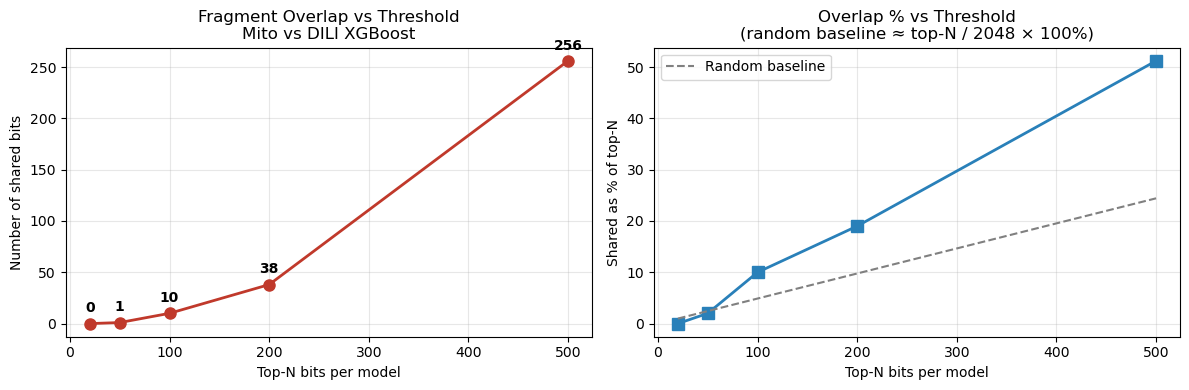


Top-100 overlap: 10 shared bits
Shared bits (ranked by combined importance): [1963, 1948, 728, 130, 1200, 753, 555, 1224, 1718, 1434]


[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerator
[11:00:55] DEPRECATION WARNING: please use MorganGenerat

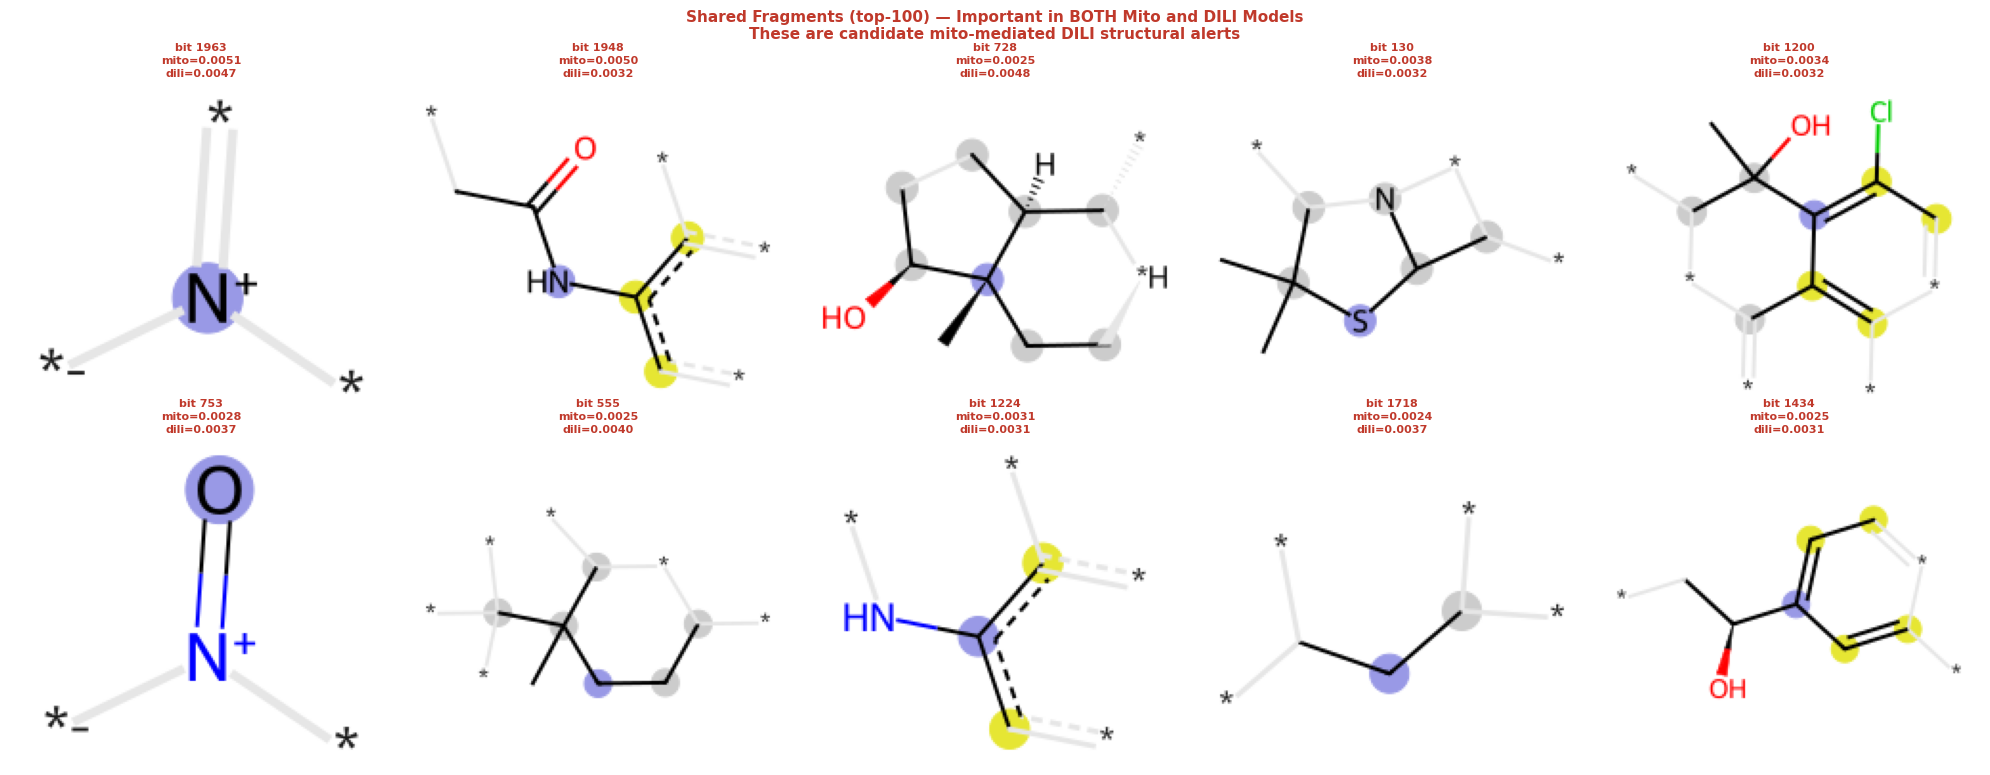

Saved → shared_fragments_mito_dili.png


In [191]:
# ── 33. Cross-Comparison: Which Bits Appear in BOTH Mito and DILI Models? ────
# Top-20 was too narrow (20/2048 = <1% of feature space).
# We now sweep thresholds: top-50, top-100, top-200 to find real overlap.

import numpy as np
import matplotlib.pyplot as plt
from rdkit.Chem import Draw, AllChem

# ── Load importances ──────────────────────────────────────────────────────────
import os
mito_path = '../mito/mito_xgb_importances.npy'
if os.path.exists(mito_path):
    mito_imp = np.load(mito_path)
    print(f"Loaded mito importances ({len(mito_imp)} bits)")
else:
    raise FileNotFoundError("Run cell 48 in the mito notebook first to save mito_xgb_importances.npy")

dili_imp = best_xgb.feature_importances_
np.save('dili_xgb_importances.npy', dili_imp)

# ── Sweep top-N thresholds ────────────────────────────────────────────────────
thresholds  = [20, 50, 100, 200, 500]
overlap_counts = []

print(f"{'Top-N':>8}  {'Mito bits':>10}  {'DILI bits':>10}  {'Shared':>8}  {'Shared %':>10}")
print("-" * 55)
for N in thresholds:
    mito_topN  = set(np.argsort(mito_imp)[::-1][:N].tolist())
    dili_topN  = set(np.argsort(dili_imp)[::-1][:N].tolist())
    shared     = mito_topN & dili_topN
    pct        = 100 * len(shared) / N
    overlap_counts.append(len(shared))
    print(f"{N:>8}  {len(mito_topN):>10}  {len(dili_topN):>10}  {len(shared):>8}  {pct:>9.1f}%")

# ── Plot overlap vs threshold ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(thresholds, overlap_counts, 'o-', color='#c0392b', linewidth=2, markersize=8)
axes[0].set_xlabel('Top-N bits per model')
axes[0].set_ylabel('Number of shared bits')
axes[0].set_title('Fragment Overlap vs Threshold\nMito vs DILI XGBoost')
axes[0].grid(True, alpha=0.3)
for x, y in zip(thresholds, overlap_counts):
    axes[0].annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 8),
                     ha='center', fontweight='bold')

pcts = [100 * c / N for c, N in zip(overlap_counts, thresholds)]
axes[1].plot(thresholds, pcts, 's-', color='#2980b9', linewidth=2, markersize=8)
axes[1].set_xlabel('Top-N bits per model')
axes[1].set_ylabel('Shared as % of top-N')
axes[1].set_title('Overlap % vs Threshold\n(random baseline ≈ top-N / 2048 × 100%)')
axes[1].grid(True, alpha=0.3)
# Random baseline line
random_baseline = [100 * N / 2048 for N in thresholds]
axes[1].plot(thresholds, random_baseline, '--', color='gray', linewidth=1.5, label='Random baseline')
axes[1].legend()

plt.tight_layout()
plt.savefig('fragment_overlap_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Draw shared fragments at the best threshold ───────────────────────────────
# Use top-100 as the working threshold
N_use       = 100
mito_top    = set(np.argsort(mito_imp)[::-1][:N_use].tolist())
dili_top    = set(np.argsort(dili_imp)[::-1][:N_use].tolist())
shared_bits = sorted(mito_top & dili_top,
                     key=lambda b: mito_imp[b] + dili_imp[b], reverse=True)

print(f"\nTop-{N_use} overlap: {len(shared_bits)} shared bits")
print("Shared bits (ranked by combined importance):", shared_bits[:15])

if shared_bits:
    smiles_list = df_test_view['csmi'].astype(str).tolist()
    imgs, caps  = [], []
    for bit in shared_bits[:10]:
        for smi in smiles_list:
            mol = Chem.MolFromSmiles(smi)
            if mol is None: continue
            bit_info = {}
            AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048, bitInfo=bit_info)
            if bit in bit_info:
                imgs.append(Draw.DrawMorganBit(mol, bit, bit_info, molSize=(200, 170)))
                caps.append(f"bit {bit}\nmito={mito_imp[bit]:.4f}\ndili={dili_imp[bit]:.4f}")
                break

    ncols = min(len(imgs), 5)
    nrows = (len(imgs) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
    axes_flat  = np.array(axes).flatten() if len(imgs) > 1 else [axes]
    fig.suptitle(f"Shared Fragments (top-{N_use}) — Important in BOTH Mito and DILI Models\n"
                 "These are candidate mito-mediated DILI structural alerts",
                 fontsize=11, fontweight='bold', color='#c0392b')
    for ax, img, cap in zip(axes_flat, imgs, caps):
        ax.imshow(img)
        ax.set_title(cap, fontsize=8, color='#c0392b', fontweight='bold', linespacing=1.4)
        ax.axis('off')
    for ax in axes_flat[len(imgs):]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig('shared_fragments_mito_dili.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved → shared_fragments_mito_dili.png")
else:
    print("Still no overlap at top-100. Try N_use=200 or check that mito importances loaded correctly.")